# Figure S4: surface freshwater flux terms, Atlantic + GIN 60-65N, 8xCO2

Each term in 8xCO2 (15-year Butterworth filter) with its piControl mean as a dashed line of the same color.
Runoff is liquid plus ice runoff. Sea ice is melt plus the salt flux expressed as freshwater:
`MELT_F - (1000/34.7) SALT_F`, with `SALT_F` positive into the ocean.

Inputs: `SFWF_terms_ann_atlGIN60-65N_{8x,control}.nc`

In [1]:
import numpy as np
import xarray as xr
import matplotlib
import matplotlib.pyplot as plt
import common

matplotlib.rc('font', size=16)

In [2]:
model_years, terms_8x = common.freshwater_terms('8x')
_, terms_control = common.freshwater_terms('control')
years = model_years - common.BRANCH_YEAR

# Mean of each term over each run's whole record
for name in terms_8x:
    print(f'{name:<14} 8x {terms_8x[name].mean():+.3f} | piControl {terms_control[name].mean():+.3f} mm/day')

Precipitation  8x +3.557 | piControl +3.041 mm/day
Evaporation    8x -2.475 | piControl -2.726 mm/day
Runoff         8x +0.642 | piControl +0.467 mm/day
Sea ice        8x +0.005 | piControl +2.855 mm/day
Total          8x +1.729 | piControl +3.638 mm/day


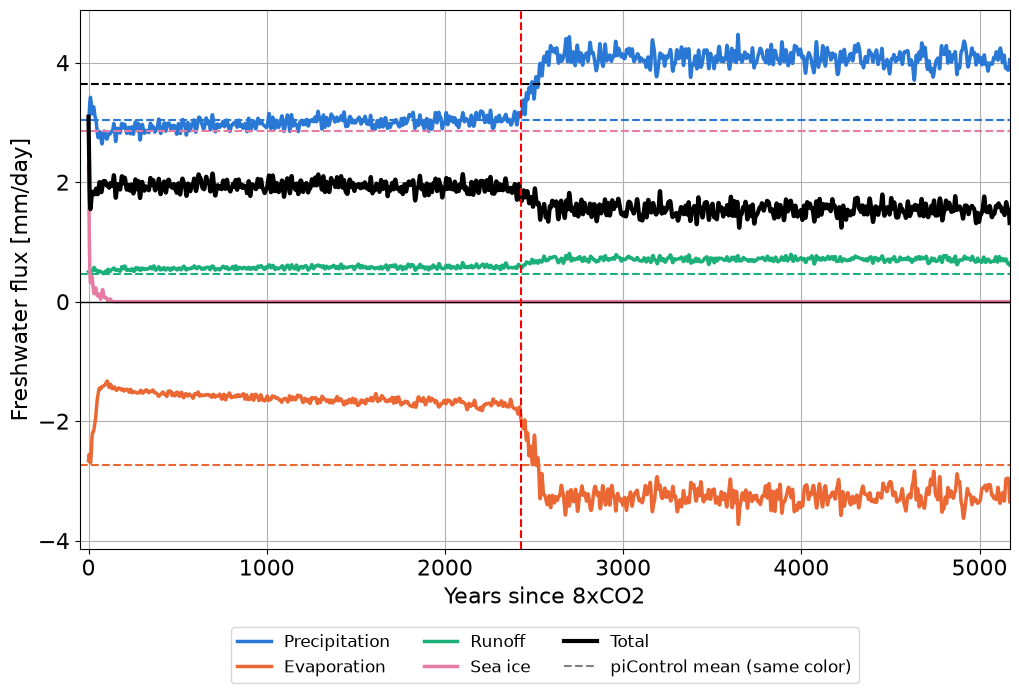

In [3]:
colors = {'Precipitation': '#2a78d6', 'Evaporation': '#eb6834', 'Runoff': '#1baf7a', 'Sea ice': '#e87ba4'}

fig, ax = plt.subplots(figsize=(12, 7))
for name, color in colors.items():
    ax.plot(years, common.butterworth_lowpass(terms_8x[name]), color=color, linewidth=2.5, label=name)
    ax.axhline(terms_control[name].mean(), color=color, linewidth=1.5, linestyle='--')
ax.plot(years, common.butterworth_lowpass(terms_8x['Total']), color='black', linewidth=3, label='Total')
ax.axhline(terms_control['Total'].mean(), color='black', linewidth=1.5, linestyle='--')
ax.plot([], [], color='grey', linestyle='--', linewidth=1.5, label='piControl mean (same color)')
ax.axhline(0, color='black', linewidth=1)
ax.axvline(common.RECOVERY_YEAR, linestyle='--', color='red')
ax.set_xlim(years[0] - common.X_START_PAD, years[-1])
ax.grid()
ax.legend(fontsize=12, ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.13))
ax.set_xlabel('Years since 8xCO2')
ax.set_ylabel('Freshwater flux [mm/day]')
plt.savefig(common.figure_path('figS4_freshwater_flux_terms.png'), dpi=150, bbox_inches='tight')
plt.show()